In [87]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3

In [88]:
# conecta a la base de datos inmobiliario.sqlite y carga la tabla 'tablon_analitico'
conn = sqlite3.connect(r"datos\intermedios\inmobiliario.sqlite")
df = pd.read_sql_query("SELECT * FROM tablon_analitico", conn)
df

,id,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price_per_night,minimum_nights,availability_365,...,estimated_occupancy_l365d,total_night_price,anual_income,estimated_m2,aprox_total_cost,poi_score,bedrooms_category,bathrooms_category,accommodates_category,margen_bruto
0,23205290,Hermosilla III by Home at Homes,Barrio de Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,83,...,28,387.0,10836.0,50.0,407437.50,40.588730,1 room,1 bathroom,2 accommodates,2.659549
1,23269747,5 Stars Short-Term Rental apartment at Plaza M...,Centro,Sol,40.414429,-3.707760,Entire home/apt,414.0,1.0,183,...,255,414.0,105570.0,65.0,378836.25,59.268188,2 rooms,1 bathroom,5+ accommodates,27.866921
2,23287977,Great Location! CALLAO SQUARE II,Centro,Sol,40.419820,-3.706630,Entire home/apt,213.0,3.0,53,...,255,213.0,54315.0,65.0,378836.25,60.254806,2 rooms,1 bathroom,4 accommodates,14.337329
3,23301767,Espléndido Apartamento en Cava Baja - La Latina,Centro,Palacio,40.413430,-3.708200,Entire home/apt,166.0,2.0,312,...,255,166.0,42330.0,50.0,291412.50,57.336408,1 room,1 bathroom,4 accommodates,14.525801
4,23351387,Madrid Chueca · Renovated 2026 · 6 pax · Gran Vía,Centro,Justicia,40.420680,-3.701230,Entire home/apt,204.0,1.0,69,...,255,204.0,52020.0,90.0,524542.50,59.422858,3 rooms,2 bathrooms,5+ accommodates,9.917214
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11766,1770448052441691419,New 2BR Apartment • 2 Bathrooms • Central Madrid,Chamberí,Trafalgar,40.430720,-3.702710,Entire home/apt,355.0,1.0,68,...,12,355.0,4260.0,65.0,446501.25,41.178598,2 rooms,1 bathroom,5+ accommodates,0.954085
11767,1770999619265103890,Confortable habitación baño privado cerca Bern...,Tetuán,Berruguete,40.458283,-3.704785,Private room,68.0,1.0,241,...,6,68.0,408.0,50.0,231037.50,11.778861,1 room,1 bathroom,2 accommodates,0.176595
11768,1771986852996662930,Habitacion en madrid,Ciudad Lineal,Pueblo Nuevo,40.434795,-3.640323,Private room,70.0,1.0,352,...,12,70.0,840.0,50.0,196575.00,6.920594,1 room,1 bathroom,2 accommodates,0.427318
11769,1772228846536016452,Habitación Among Latinas,Centro,Palacio,40.409911,-3.710158,Private room,90.0,1.0,74,...,6,90.0,540.0,50.0,291412.50,49.310577,1 room,1 bathroom,1 accommodate,0.185304


In [89]:
distrito = "neighbourhood_group"
barrio = "neighbourhood"
precio = "price_per_night"
ocupacion = "estimated_occupancy_l365d"
tamano = "estimated_m2"

In [90]:
# Media, mediana, rango y percentiles del precio por noche
display(
    df[precio]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .to_frame()
    .T
)

# Por distrito
precio_distrito = (
    df.groupby(distrito)
    .agg(
        anuncios=("id", "nunique"),
        precio_medio=(precio, "mean"),
        precio_mediano=(precio, "median"),
        minimo=(precio, "min"),
        maximo=(precio, "max"),
    )
    .sort_values("precio_medio", ascending=False)
)
display(precio_distrito.round(2))

# Por barrio
precio_barrio = (
    df.groupby([distrito, barrio])
    .agg(
        anuncios=("id", "nunique"),
        precio_medio=(precio, "mean"),
        precio_mediano=(precio, "median"),
        minimo=(precio, "min"),
        maximo=(precio, "max"),
    )
    .sort_values("precio_medio", ascending=False)
)
display(precio_barrio.round(2))

,count,mean,std,min,25%,50%,75%,90%,max
price_per_night,11771.0,180.356809,123.677181,20.0,100.0,154.0,223.0,328.0,999.0


,anuncios,precio_medio,precio_mediano,minimo,maximo
neighbourhood_group,,,,,
Barrio de Salamanca,701,241.70,195.0,28.0,967.0
Centro,5212,210.85,180.0,20.0,999.0
Chamberí,600,189.66,167.0,21.0,969.0
Retiro,423,184.52,156.0,29.0,968.0
Chamartín,414,184.01,153.0,32.0,999.0
Moncloa,288,171.87,151.0,21.0,945.0
Arganzuela,614,165.48,150.0,22.0,629.0
Tetuán,800,144.50,129.5,23.0,979.0
Hortaleza,273,137.94,117.0,34.0,590.0


anuncios  precio_medio  precio_mediano  \
neighbourhood_group neighbourhood                                              
Barrio de Salamanca Recoletos              145        324.07           268.0   
                    Castellana              65        269.35           200.0   
Chamartín           El Viso                 38        262.24           197.5   
Barrio de Salamanca Goya                   157        256.57           207.0   
Retiro              Jerónimos               49        247.67           205.0   
...                                        ...           ...             ...   
Villaverde          Los Angeles             22         68.64            67.5   
Hortaleza           Apostol Santiago        21         63.48            50.0   
Moratalaz           Vinateros                8         61.75            48.5   
                    Pavones                  3         51.67            35.0   
                    Horcajo                  2         48.50            48.5   

                                      minimo  maximo  
neighbourhood_group neighbourhood                     
Barrio de Salamanca Recoletos          103.0   967.0  
                    Castellana          45.0   860.0  
Chamartín           El Viso             32.0   999.0  
Barrio de Salamanca Goya                41.0   926.0  
Retiro              Jerónimos           39.0   968.0  
...                                      ...     ...  
Villaverde          Los Angeles         21.0   177.0  
Hortaleza           Apostol Santiago    35.0   174.0  
Moratalaz           Vinateros           31.0   134.0  
                    Pavones             33.0    87.0  
                    Horcajo             44.0    53.0  

[125 rows x 5 columns]

In [91]:
# Relación del precio con variables numéricas
factores_numericos = [
    "minimum_nights",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "estimated_m2",
    "review_scores_location",
    "poi_score",
]
factores_numericos = [c for c in factores_numericos if c in df.columns]

display(
    df[[precio] + factores_numericos]
    .corr(method="spearman")[precio]
    .drop(precio)
    .sort_values(ascending=False)
    .to_frame("correlacion_spearman")
)

# Comparación del precio por categorías
for columna in [
    "room_type",
    "bedrooms_category",
    "bathrooms_category",
    "accommodates_category",
]:
    if columna in df.columns:
        print(f"Precio por {columna}")
        display(
            df.groupby(columna)
            .agg(
                anuncios=("id", "nunique"),
                precio_medio=(precio, "mean"),
                precio_mediano=(precio, "median"),
            )
            .sort_values("precio_medio", ascending=False)
            .round(2)
        )

,correlacion_spearman
accommodates,0.616450
beds,0.517492
estimated_m2,0.479869
bedrooms,0.479869
poi_score,0.348799
bathrooms,0.295122
review_scores_location,0.199819
minimum_nights,-0.059805


Precio por room_type


,anuncios,precio_medio,precio_mediano
room_type,,,
Entire home/apt,8654,211.76,179.0
Private room,3054,94.44,74.0
Shared room,63,31.37,24.0


Precio por bedrooms_category


,anuncios,precio_medio,precio_mediano
bedrooms_category,,,
4 rooms,145,403.28,393.0
3 rooms,885,313.05,275.0
2 rooms,2791,235.39,208.0
5+ rooms,22,208.82,134.5
1 room,7928,142.01,129.0


Precio por bathrooms_category


,anuncios,precio_medio,precio_mediano
bathrooms_category,,,
2 bathrooms,1047,323.66,287.0
3 bathrooms,5,249.20,208.0
1 bathroom,10719,166.33,147.0


Precio por accommodates_category


,anuncios,precio_medio,precio_mediano
accommodates_category,,,
5+ accommodates,2198,286.81,246.0
4 accommodates,3307,208.54,180.0
3 accommodates,1222,161.85,149.5
2 accommodates,4000,134.80,120.0
1 accommodate,1044,63.17,53.0


,anuncios,tamano_medio,precio_medio,precio_mediano
grupo_tamano,,,,
"(49.999, 65.0]",10719,53.91,166.33,147.0
"(65.0, 210.0]",1052,95.40,323.31,286.5


Correlación tamaño-precio: 0.47986923541553134


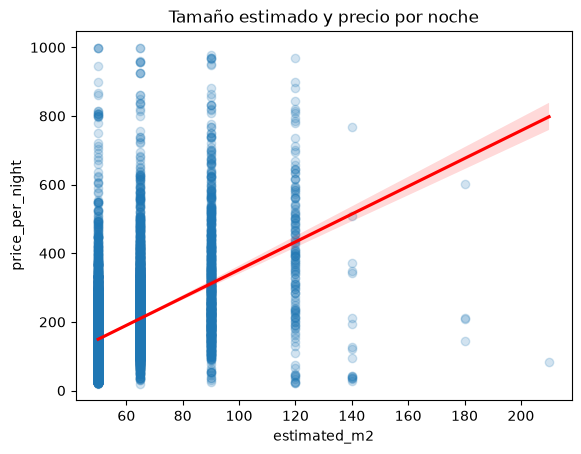

anuncios  precio_medio  ocupacion_media
neighbourhood_group neighbourhood                                          
Centro              Embajadores         1328        180.01           148.68
                    Universidad         1065        208.82           151.69
                    Palacio              962        217.77           154.41
                    Sol                  686        239.45           158.02
                    Justicia             619        218.73           144.04
...                                      ...           ...              ...
Latina              Cuatro Vientos         4         80.50            73.50
Moratalaz           Pavones                3         51.67           176.00
Moncloa             Valdemarín             3        125.67            50.00
Fuencarral          El Goloso              2        101.00           247.50
Moratalaz           Horcajo                2         48.50            30.00

[125 rows x 3 columns]

,anuncios,precio_medio
anuncios,1.000000,0.609819
precio_medio,0.609819,1.000000


In [92]:
# Agrupar los inmuebles en cinco grupos de tamaño
df["grupo_tamano"] = pd.qcut(df[tamano], q=5, duplicates="drop")

display(
    df.groupby("grupo_tamano", observed=True)
    .agg(
        anuncios=("id", "nunique"),
        tamano_medio=(tamano, "mean"),
        precio_medio=(precio, "mean"),
        precio_mediano=(precio, "median"),
    )
    .round(2)
)

print("Correlación tamaño-precio:", df[[tamano, precio]].corr(method="spearman").iloc[0, 1])

sns.regplot(
    data=df, x=tamano, y=precio,
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"},
)
plt.title("Tamaño estimado y precio por noche")
plt.show()

# Competencia aproximada: anuncios disponibles en cada barrio
competencia = (
    df.groupby([distrito, barrio])
    .agg(
        anuncios=("id", "nunique"),
        precio_medio=(precio, "mean"),
        ocupacion_media=(ocupacion, "mean"),
    )
    .sort_values("anuncios", ascending=False)
)

display(competencia.round(2))
display(competencia[["anuncios", "precio_medio"]].corr(method="spearman"))

In [93]:
# precio por tipo de alquiler

display(
    df.groupby("room_type")
    .agg(
        anuncios=("id", "nunique"),
        precio_medio=(precio, "mean"),
        precio_mediano=(precio, "median"),
        precio_minimo=(precio, "min"),
        precio_maximo=(precio, "max"),
    )
    .sort_values("precio_medio", ascending=False)
    .round(2)
)

,anuncios,precio_medio,precio_mediano,precio_minimo,precio_maximo
room_type,,,,,
Entire home/apt,8654,211.76,179.0,28.0,999.0
Private room,3054,94.44,74.0,20.0,999.0
Shared room,63,31.37,24.0,20.0,159.0


In [94]:
#Ocupación: media, rankings y probabilidad por nivel

# Media y distribución de la ocupación
display(df[ocupacion].describe().to_frame().T)

# Por distrito
ocupacion_distrito = (
    df.groupby(distrito)
    .agg(
        anuncios=("id", "nunique"),
        ocupacion_media=(ocupacion, "mean"),
        ocupacion_mediana=(ocupacion, "median"),
    )
    .sort_values("ocupacion_media", ascending=False)
)
display(ocupacion_distrito.round(2))

# Por barrio
ocupacion_barrio = (
    df.groupby([distrito, barrio])
    .agg(
        anuncios=("id", "nunique"),
        ocupacion_media=(ocupacion, "mean"),
        ocupacion_mediana=(ocupacion, "median"),
    )
    .sort_values("ocupacion_media", ascending=False)
)
display(ocupacion_barrio.round(2))

# Porcentaje de anuncios de cada nivel de ocupación dentro de cada distrito
df["nivel_ocupacion"] = pd.cut(
    df[ocupacion],
    bins=[-1, 90, 180, 270, 365],
    labels=["0–90 días", "91–180 días", "181–270 días", "271–365 días"],
)

probabilidad_ocupacion = (
    pd.crosstab(df[distrito], df["nivel_ocupacion"], normalize="index") * 100
).sort_values("181–270 días", ascending=False)
display(probabilidad_ocupacion.round(1))

,count,mean,std,min,25%,50%,75%,max
estimated_occupancy_l365d,11771.0,141.420525,92.53614,6.0,54.0,138.0,255.0,255.0


,anuncios,ocupacion_media,ocupacion_mediana
neighbourhood_group,,,
Barajas,93,162.54,192.0
Centro,5212,151.67,156.0
Villa de Vallecas,38,151.13,168.0
Arganzuela,614,150.52,156.0
Retiro,423,145.06,150.0
Vicálvaro,34,140.06,120.0
Barrio de Salamanca,701,138.51,132.0
Puente de Vallecas,365,134.72,120.0
Tetuán,800,134.44,126.0


anuncios  ocupacion_media  \
neighbourhood_group neighbourhood                                 
Fuencarral          El Goloso                2           247.50   
Barajas             Corralejos              10           231.40   
Hortaleza           Apostol Santiago        21           185.48   
Moratalaz           Fontarrón               13           183.46   
San Blas            Salvador                 9           178.00   
...                                        ...              ...   
Moratalaz           Media Legua             15            82.33   
                    Marroquina              11            75.09   
Latina              Cuatro Vientos           4            73.50   
Moncloa             Valdemarín               3            50.00   
Moratalaz           Horcajo                  2            30.00   

                                      ocupacion_mediana  
neighbourhood_group neighbourhood                        
Fuencarral          El Goloso                     247.5  
Barajas             Corralejos                    255.0  
Hortaleza           Apostol Santiago              255.0  
Moratalaz           Fontarrón                     255.0  
San Blas            Salvador                      210.0  
...                                                 ...  
Moratalaz           Media Legua                    60.0  
                    Marroquina                     30.0  
Latina              Cuatro Vientos                 78.0  
Moncloa             Valdemarín                     24.0  
Moratalaz           Horcajo                        30.0  

[125 rows x 3 columns]

nivel_ocupacion,0–90 días,91–180 días,181–270 días
neighbourhood_group,,,
Barajas,37.6,10.8,51.6
Arganzuela,34.4,20.8,44.8
Villa de Vallecas,28.9,26.3,44.7
Centro,34.2,21.3,44.5
Retiro,34.5,25.3,40.2
Puente de Vallecas,43.3,19.7,37.0
Ciudad Lineal,45.6,17.5,36.9
Tetuán,42.8,20.5,36.8
Barrio de Salamanca,37.1,27.5,35.4


## Análisis con minicubo

In [95]:
dimensiones = [
    'neighbourhood_group',
    'neighbourhood',
    'room_type',
    'bedrooms_category',
    'bathrooms_category',
    'accommodates_category',
]

metricas = [
    'price_per_night',
    'estimated_occupancy_l365d',
    'anual_income',
    'aprox_total_cost',
    'margen_bruto'
]

# Pasar las dimensiones a formato transaccional sin cruzarlas entre si.
minicubo_largo = df[metricas + dimensiones].melt(
    id_vars=metricas,
    value_vars=dimensiones,
    var_name='dimension',
    value_name='valor',
)

minicubo_largo = minicubo_largo[['dimension', 'valor', 'price_per_night', 'estimated_occupancy_l365d', 'anual_income', 'aprox_total_cost', 'margen_bruto']]

minicubo_largo

,dimension,valor,price_per_night,estimated_occupancy_l365d,anual_income,aprox_total_cost,margen_bruto
0,neighbourhood_group,Barrio de Salamanca,387.0,28,10836.0,407437.50,2.659549
1,neighbourhood_group,Centro,414.0,255,105570.0,378836.25,27.866921
2,neighbourhood_group,Centro,213.0,255,54315.0,378836.25,14.337329
3,neighbourhood_group,Centro,166.0,255,42330.0,291412.50,14.525801
4,neighbourhood_group,Centro,204.0,255,52020.0,524542.50,9.917214
...,...,...,...,...,...,...,...
70621,accommodates_category,5+ accommodates,355.0,12,4260.0,446501.25,0.954085
70622,accommodates_category,2 accommodates,68.0,6,408.0,231037.50,0.176595
70623,accommodates_category,2 accommodates,70.0,12,840.0,196575.00,0.427318
70624,accommodates_category,1 accommodate,90.0,6,540.0,291412.50,0.185304


In [96]:
# Contar anuncios y resumir cada metrica por dimension y valor.
agregaciones = {'anuncios': (metricas[0], 'size')}
for metrica in metricas:
    agregaciones[f'{metrica}_media'] = (metrica, 'mean')
    agregaciones[f'{metrica}_mediana'] = (metrica, 'median')

minicubo = (
    minicubo_largo
    .groupby(['dimension', 'valor'], dropna=False)
    .agg(**agregaciones)
    .sort_index()
)

display(minicubo.round(2))

anuncios  price_per_night_media  \
dimension             valor                                                
accommodates_category 1 accommodate          1044                  63.17   
                      2 accommodates         4000                 134.80   
                      3 accommodates         1222                 161.85   
                      4 accommodates         3307                 208.54   
                      5+ accommodates        2198                 286.81   
...                                           ...                    ...   
neighbourhood_group   Villa de Vallecas        38                 115.71   
                      Villaverde              106                 108.92   
room_type             Entire home/apt        8654                 211.76   
                      Private room           3054                  94.44   
                      Shared room              63                  31.37   

                                         price_per_night_mediana  \
dimension             valor                                        
accommodates_category 1 accommodate                         53.0   
                      2 accommodates                       120.0   
                      3 accommodates                       149.5   
                      4 accommodates                       180.0   
                      5+ accommodates                      246.0   
...                                                          ...   
neighbourhood_group   Villa de Vallecas                    111.0   
                      Villaverde                           102.0   
room_type             Entire home/apt                      179.0   
                      Private room                          74.0   
                      Shared room                           24.0   

                                         estimated_occupancy_l365d_media  \
dimension             valor                                                
accommodates_category 1 accommodate                               119.25   
                      2 accommodates                              139.60   
                      3 accommodates                              148.46   
                      4 accommodates                              145.99   
                      5+ accommodates                             144.47   
...                                                                  ...   
neighbourhood_group   Villa de Vallecas                           151.13   
                      Villaverde                                  105.24   
room_type             Entire home/apt                             147.34   
                      Private room                                125.82   
                      Shared room                                  84.52   

                                         estimated_occupancy_l365d_mediana  \
dimension             valor                                                  
accommodates_category 1 accommodate                                   96.0   
                      2 accommodates                                 132.0   
                      3 accommodates                                 156.0   
                      4 accommodates                                 144.0   
                      5+ accommodates                                138.0   
...                                                                    ...   
neighbourhood_group   Villa de Vallecas                              168.0   
                      Villaverde                                      78.0   
room_type             Entire home/apt                                150.0   
                      Private room                                   108.0   
                      Shared room                                     48.0   

                                         anual_income_media  \
dimension             valor                                   
accommodates_category 1 accommodate  

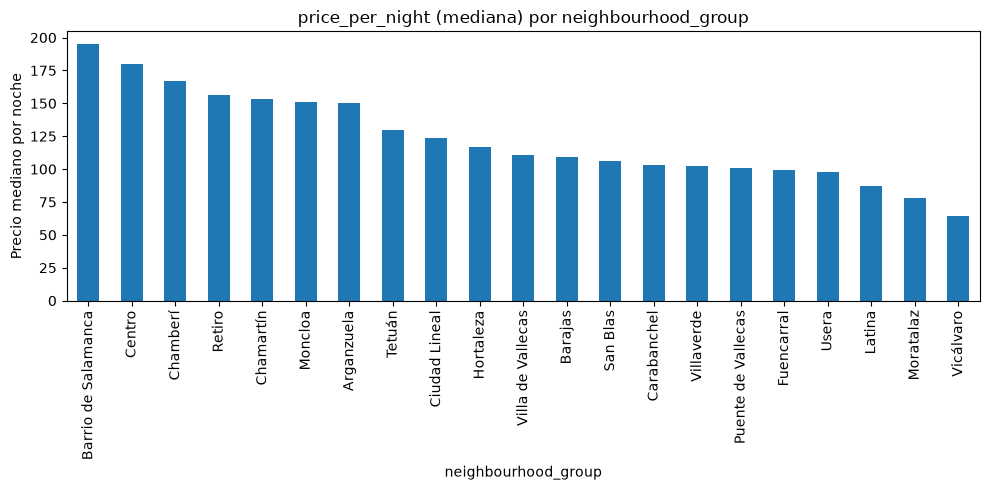

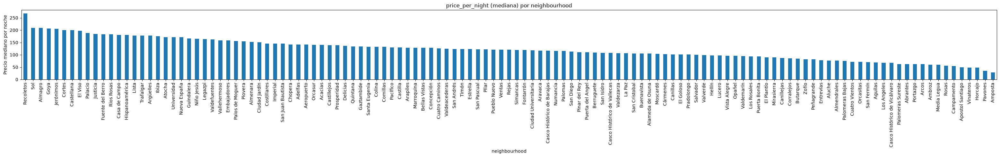

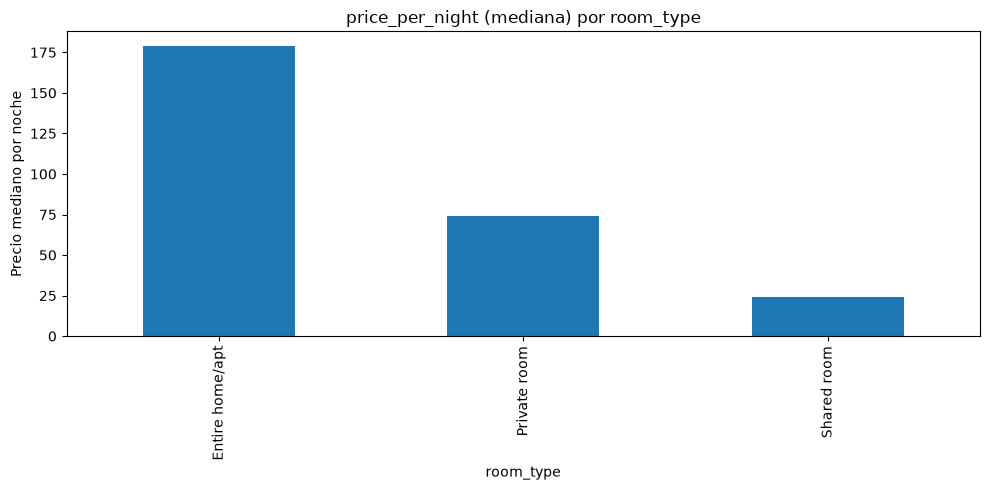

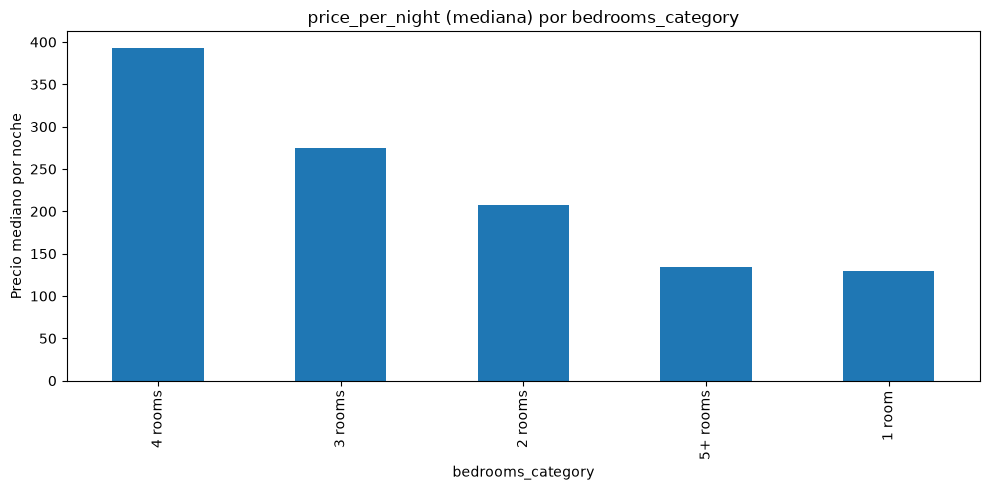

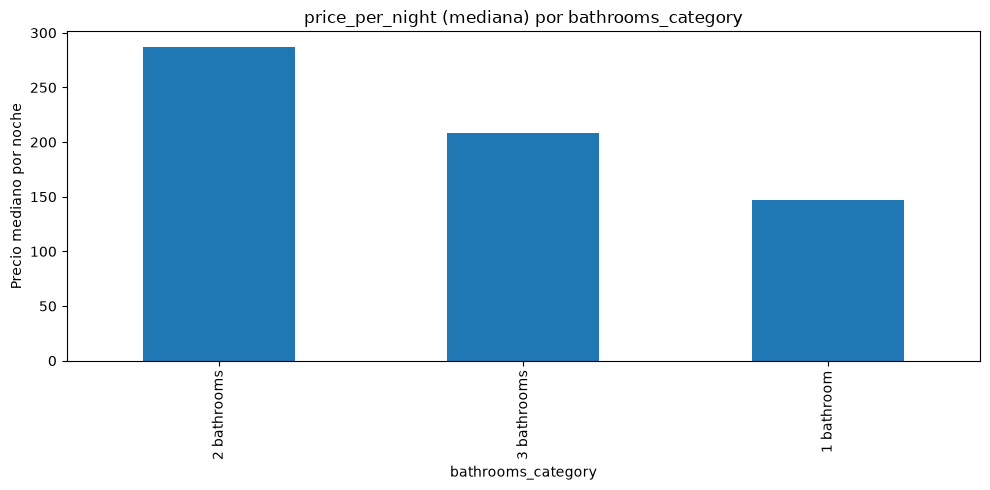

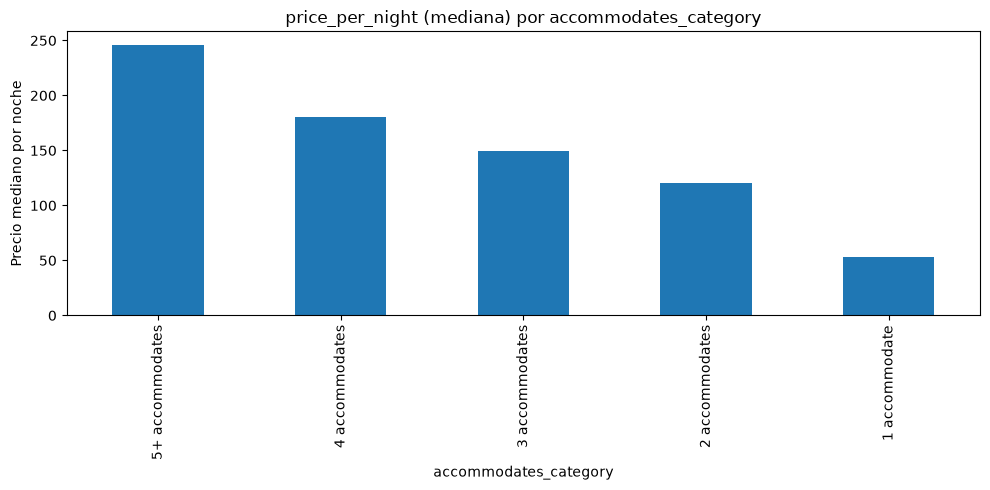

In [97]:
metrica = 'price_per_night'
columna_metrica = f'{metrica}_mediana'

for dimension in dimensiones:
    datos = minicubo.loc[dimension, columna_metrica].sort_values(ascending=False)
    ancho = max(10, len(datos) * 0.25)

    ax = datos.plot.bar(figsize=(ancho, 5))
    ax.set_title(f'{metrica} (mediana) por {dimension}')
    ax.set_xlabel(dimension)
    ax.set_ylabel('Precio mediano por noche')
    ax.tick_params(axis='x', labelrotation=90)
    plt.tight_layout()
    plt.show()


## Conclusiones: precio por noche

Los gráficos comparan la mediana de `price_per_night` entre las categorías de cada dimensión. La mediana reduce la influencia de anuncios con precios extremos.

- **Distrito (`neighbourhood_group`):** Barrio de Salamanca presenta la mediana más alta (195), seguido de Centro (180) y Chamberí (167). En el extremo inferior están Vicálvaro (64,5) y Moratalaz (78). Centro cuenta con 5.212 anuncios, mientras que Vicálvaro solo tiene 34.
- **Barrio (`neighbourhood`):** Recoletos destaca con 268; Sol y Almagro alcanzan 209,5. En el extremo bajo aparecen Amposta (28) y Pavones (35), pero con solo 5 y 3 anuncios, respectivamente. Esas medianas deben interpretarse con cautela; los barrios tienen tamaños de muestra muy distintos.
- **Tipo de alojamiento (`room_type`):** La mediana es 179 para viviendas completas, 74 para habitaciones privadas y 24 para habitaciones compartidas. Las habitaciones compartidas solo reúnen 63 anuncios, frente a 8.654 viviendas completas.
- **Número de dormitorios (`bedrooms_category`):** La mediana aumenta desde 129 en viviendas de 1 dormitorio hasta 393 en las de 4. La categoría de 5 o más dormitorios rompe esa progresión (134,5) y solo contiene 22 anuncios; conviene no interpretarla como una tendencia estable.
- **Número de baños (`bathrooms_category`):** Los anuncios con 2 baños tienen una mediana de 287, frente a 147 para 1 baño. La categoría de 3 baños marca 208, pero solo contiene 5 anuncios, por lo que su resultado es poco representativo.
- **Capacidad (`accommodates_category`):** Se observa un aumento gradual: desde 53 para 1 huésped hasta 246 para 5 o más. Es una relación con el precio total por noche, no con el precio por huésped.

**Lectura general:** ubicación, tipo y capacidad diferencian claramente los precios medianos. Son comparaciones descriptivas de una dimensión cada vez: no aíslan el efecto de las demás características ni demuestran causalidad. Las categorías con pocos anuncios requieren especial prudencia.

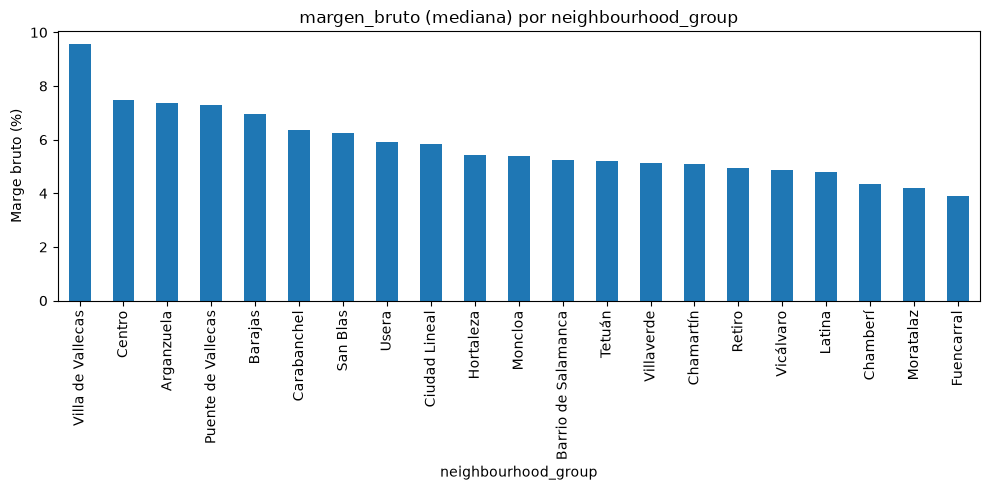

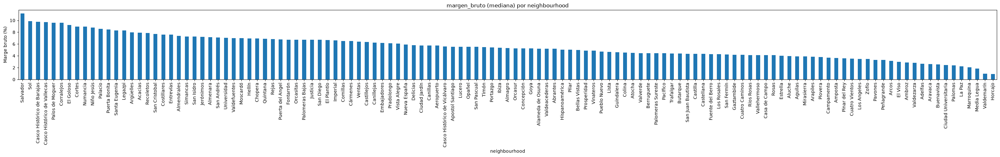

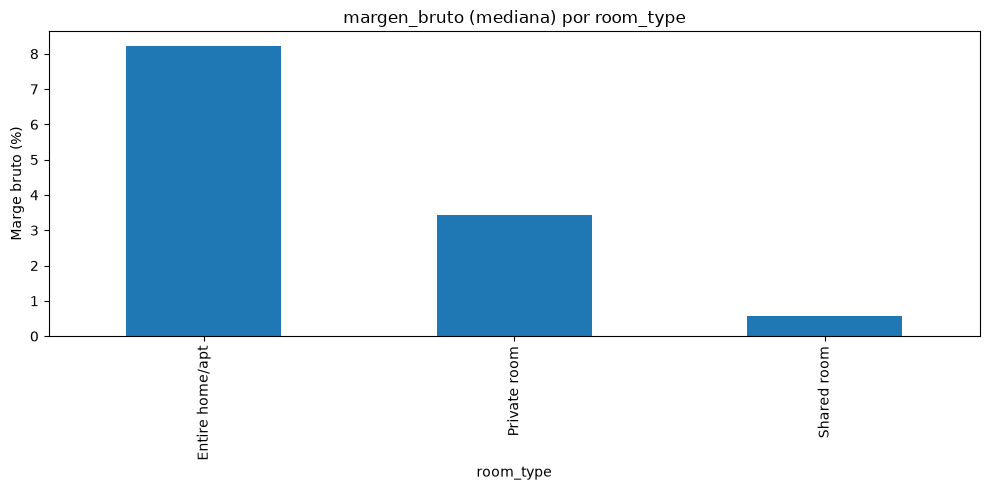

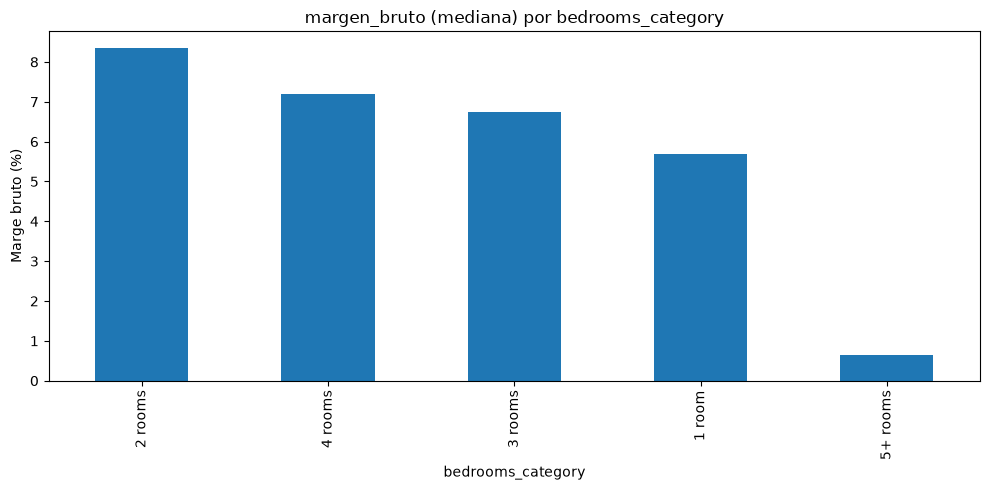

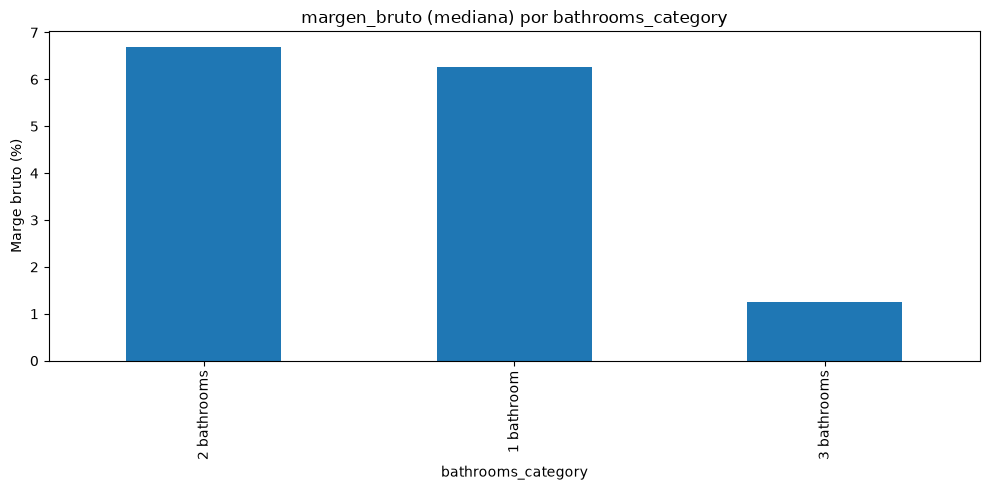

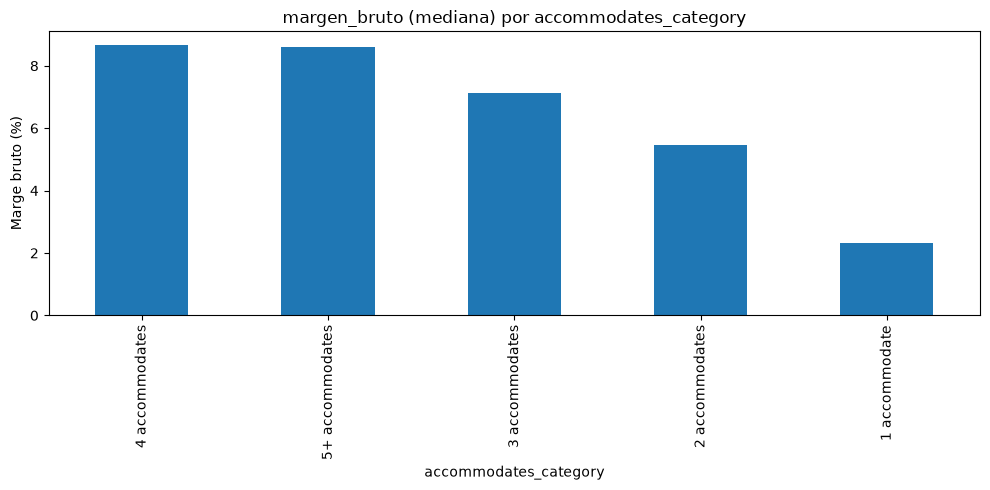

In [98]:
metrica = 'margen_bruto'
columna_metrica = f'{metrica}_mediana'

for dimension in dimensiones:
    datos = minicubo.loc[dimension, columna_metrica].sort_values(ascending=False)
    ancho = max(10, len(datos) * 0.25)

    ax = datos.plot.bar(figsize=(ancho, 5))
    ax.set_title(f'{metrica} (mediana) por {dimension}')
    ax.set_xlabel(dimension)
    ax.set_ylabel('Marge bruto (%)')
    ax.tick_params(axis='x', labelrotation=90)
    plt.tight_layout()
    plt.show()


C:\Users\fishm\AppData\Local\Temp\ipykernel_20048\4004675903.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(valores_por_distrito, vert=False)


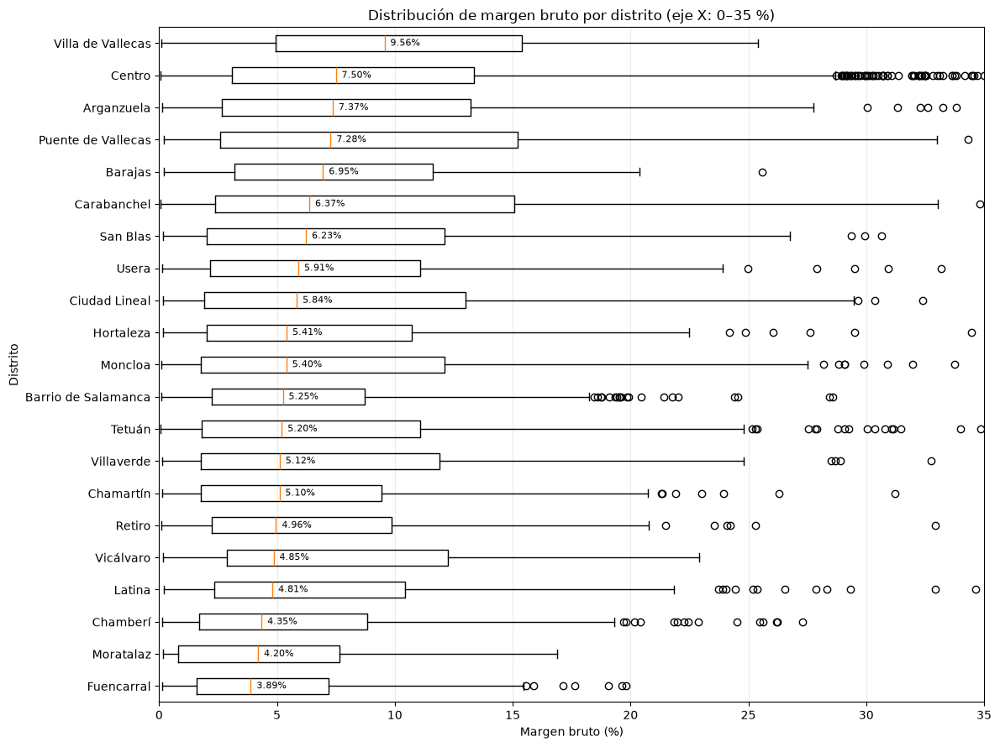

In [99]:
medianas_distrito = (
    df.groupby('neighbourhood_group')['margen_bruto']
    .median()
    .sort_values()
)
grupos_distrito = medianas_distrito.index.tolist()
valores_por_distrito = [
    df.loc[df['neighbourhood_group'].eq(grupo), 'margen_bruto'].dropna()
    for grupo in grupos_distrito
]

fig, ax = plt.subplots(figsize=(12, 9))
ax.boxplot(valores_por_distrito, vert=False)
ax.set_yticks(range(1, len(grupos_distrito) + 1), labels=grupos_distrito)

for posicion, mediana in enumerate(medianas_distrito, start=1):
    ax.annotate(
        f'{mediana:.2f}%',
        xy=(mediana, posicion),
        xytext=(5, 0),
        textcoords='offset points',
        va='center',
        fontsize=8,
    )

ax.set_xlim(0, 35)
ax.set_xlabel('Margen bruto (%)')
ax.set_ylabel('Distrito')
ax.set_title('Distribución de margen bruto por distrito (eje X: 0–35 %)')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## Análisis de la rentabilidad

Los gráficos muestran la mediana de `margen_bruto` por categoría. Esta variable se calcula como ingresos anuales estimados / coste aproximado × 100; es un indicador bruto y no equivale a rentabilidad neta.

- **Distrito (`neighbourhood_group`):** Villa de Vallecas presenta la mediana más alta (9,56 %), seguida de Centro (7,50 %) y Arganzuela (7,37 %). Villa de Vallecas solo cuenta con 38 anuncios; Centro, con 5.212. Entre los valores bajos están Fuencarral (3,89 %) y Moratalaz (4,20 %).
- **Barrio (`neighbourhood`):** Salvador alcanza 11,19 %, pero se basa en 9 anuncios. Sol (9,87 %; 686 anuncios) y los barrios Casco Histórico de Barajas (9,78 %; 34) y Casco Histórico de Vallecas (9,72 %; 29) también destacan. En el extremo bajo están Horcajo (0,92 %; 2 anuncios) y Valdemarín (0,96 %; 3); sus resultados son muy inestables por el tamaño de muestra.
- **Tipo de alojamiento (`room_type`):** Las viviendas completas tienen una mediana de 8,22 %, por encima de las habitaciones privadas (3,42 %) y compartidas (0,57 %). La categoría de habitaciones compartidas es pequeña (63 anuncios).
- **Número de dormitorios (`bedrooms_category`):** La categoría de 2 dormitorios registra la mediana más alta (8,35 %). En cambio, la de 5 o más dormitorios queda en 0,65 % y solo contiene 22 anuncios; no se observa una relación creciente y uniforme con el número de dormitorios.
- **Número de baños (`bathrooms_category`):** Las medianas de 1 y 2 baños son próximas (6,26 % y 6,69 %). La categoría de 3 baños baja a 1,24 %, pero solo tiene 5 anuncios y no permite una conclusión fiable.
- **Capacidad (`accommodates_category`):** Los valores más altos aparecen en 4 huéspedes (8,67 %) y 5 o más (8,59 %); el de 1 huésped es menor (2,31 %). La relación no aumenta de forma estrictamente monotónica.

**Interpretación:** el indicador destaca algunas categorías, pero no incorpora todos los costes ni controla simultáneamente las demás dimensiones. Conviene tratarlo como una aproximación comparativa, no como una estimación de beneficio neto ni como evidencia causal.

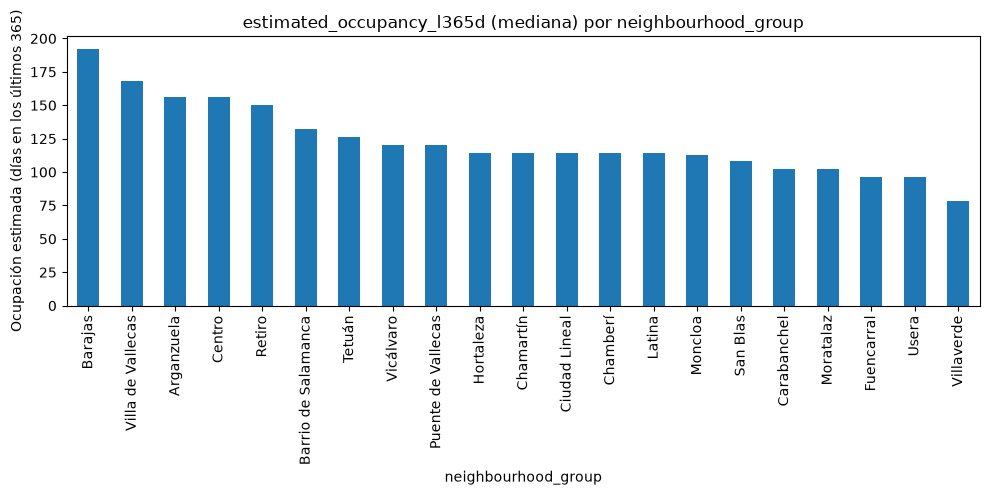

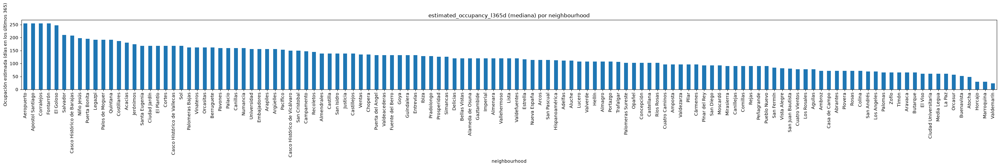

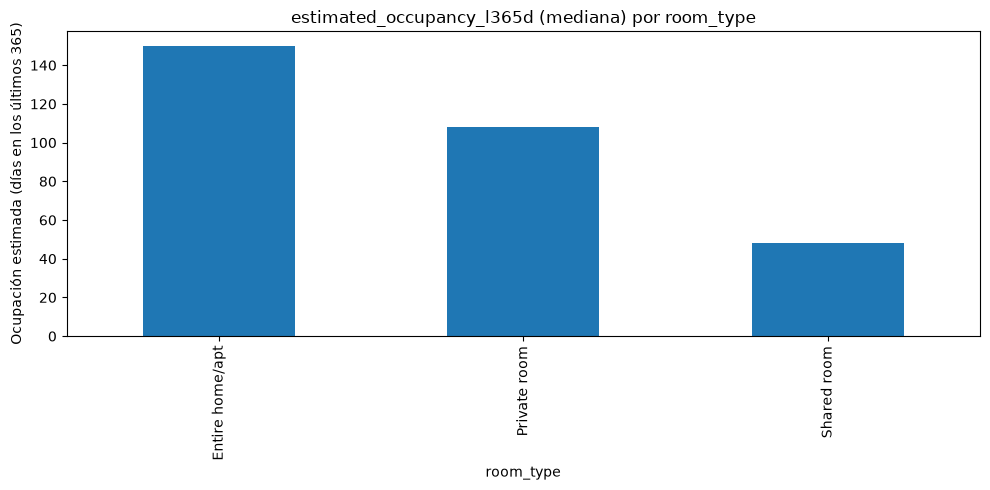

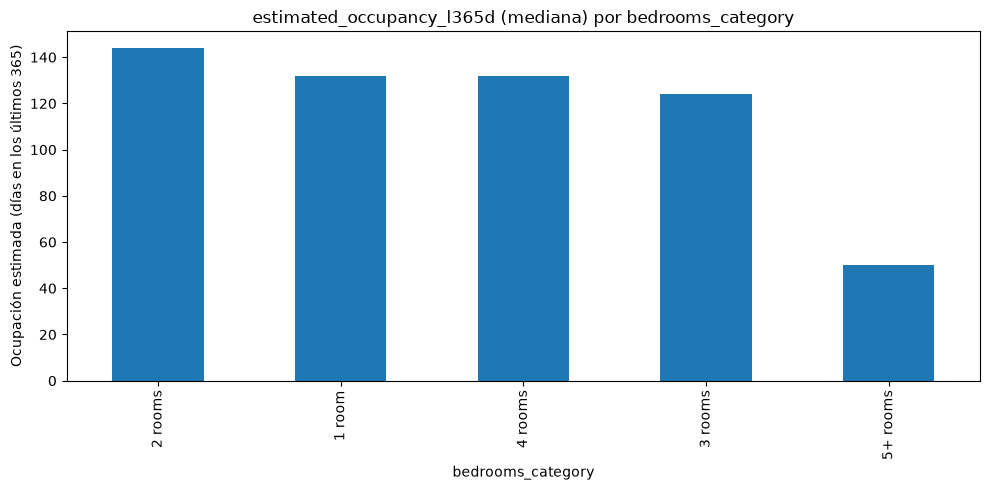

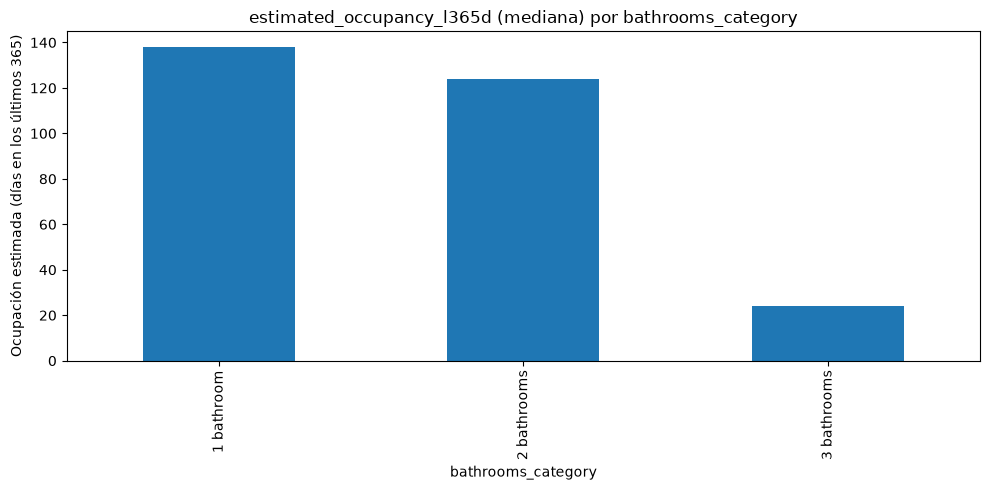

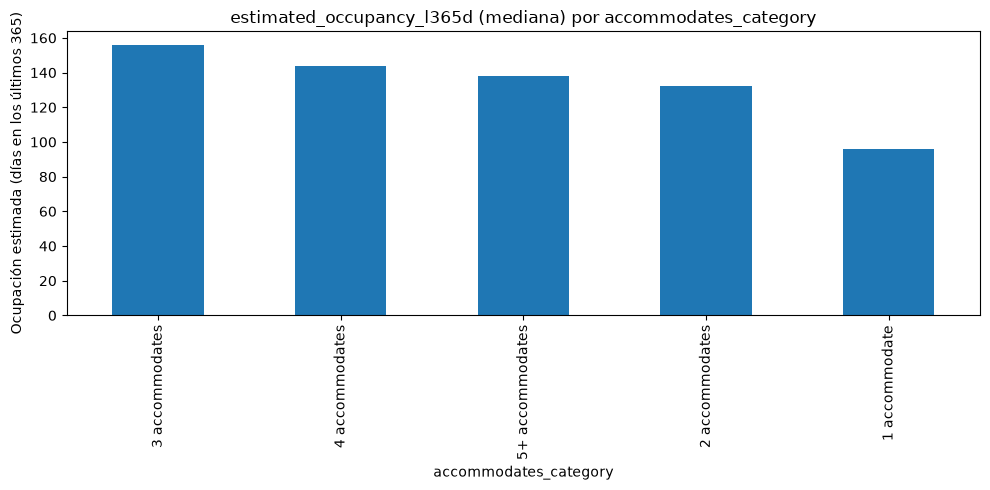

In [100]:
metrica = 'estimated_occupancy_l365d'
columna_metrica = f'{metrica}_mediana'

for dimension in dimensiones:
    datos = minicubo.loc[dimension, columna_metrica].sort_values(ascending=False)
    ancho = max(10, len(datos) * 0.25)

    ax = datos.plot.bar(figsize=(ancho, 5))
    ax.set_title(f'{metrica} (mediana) por {dimension}')
    ax.set_xlabel(dimension)
    ax.set_ylabel('Ocupación estimada (días en los últimos 365)')
    ax.tick_params(axis='x', labelrotation=90)
    plt.tight_layout()
    plt.show()


## Conclusiones: ocupación estimada

La métrica representa días de ocupación estimados durante los últimos 365 días; los gráficos comparan sus medianas.

- **Distrito (`neighbourhood_group`):** Barajas presenta la mediana más alta (192 días), seguido de Villa de Vallecas (168). Centro y Arganzuela marcan 156 días. Villaverde queda en 78 días; Fuencarral y Usera, en 96.
- **Barrio (`neighbourhood`):** Fontarrón, Corralejos, Apóstol Santiago y Aeropuerto alcanzan 255 días. Sus muestras son pequeñas (entre 7 y 21 anuncios). En el extremo inferior están Valdemarín (24 días; 3 anuncios) y Horcajo (30 días; 2), por lo que estos extremos deben interpretarse con cautela.
- **Tipo de alojamiento (`room_type`):** Las viviendas completas presentan una mediana de 150 días; las habitaciones privadas, 108; y las compartidas, 48. Estas últimas solo tienen 63 anuncios.
- **Número de dormitorios (`bedrooms_category`):** La categoría de 2 dormitorios registra 144 días. Las de 1 y 4 dormitorios tienen 132, la de 3 dormitorios 124 y la de 5 o más 50; esta última cuenta con solo 22 anuncios.
- **Número de baños (`bathrooms_category`):** La mediana es de 138 días para 1 baño y 124 para 2. La categoría de 3 baños baja a 24 días, pero solo cuenta con 5 anuncios.
- **Capacidad (`accommodates_category`):** El valor más alto corresponde a 3 huéspedes (156 días). Después aparecen 4 huéspedes (144), 5 o más (138), 2 (132) y 1 (96). A diferencia del precio, la ocupación no aumenta con la capacidad.

**Interpretación:** la ocupación varía por zona y tipo, pero no sigue una tendencia uniforme con el tamaño del alojamiento. Las medianas de categorías con pocos anuncios son menos representativas. Al tratarse de cruces unidimensionales, las diferencias son descriptivas y no aíslan el efecto de otras características.

## ¿Dónde comprar?

C:\Users\fishm\AppData\Local\Temp\ipykernel_20048\4004675903.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(valores_por_distrito, vert=False)


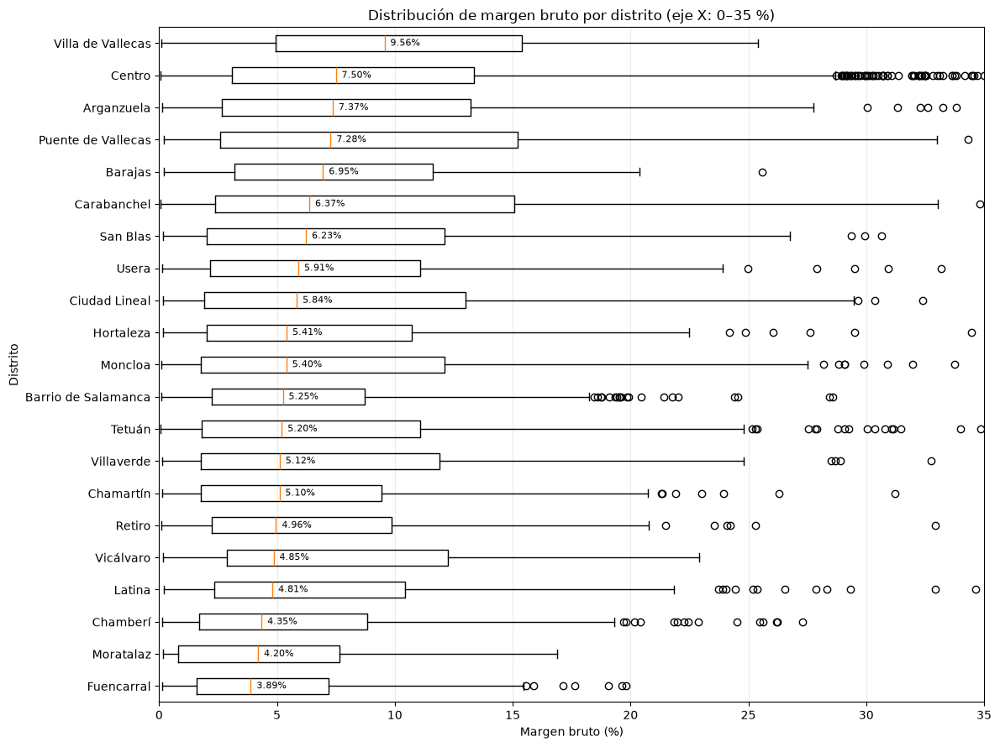

In [101]:
medianas_distrito = (
    df.groupby('neighbourhood_group')['margen_bruto']
    .median()
    .sort_values()
)
grupos_distrito = medianas_distrito.index.tolist()
valores_por_distrito = [
    df.loc[df['neighbourhood_group'].eq(grupo), 'margen_bruto'].dropna()
    for grupo in grupos_distrito
]

fig, ax = plt.subplots(figsize=(12, 9))
ax.boxplot(valores_por_distrito, vert=False)
ax.set_yticks(range(1, len(grupos_distrito) + 1), labels=grupos_distrito)

for posicion, mediana in enumerate(medianas_distrito, start=1):
    ax.annotate(
        f'{mediana:.2f}%',
        xy=(mediana, posicion),
        xytext=(5, 0),
        textcoords='offset points',
        va='center',
        fontsize=8,
    )

ax.set_xlim(0, 35)
ax.set_xlabel('Margen bruto (%)')
ax.set_ylabel('Distrito')
ax.set_title('Distribución de margen bruto por distrito (eje X: 0–35 %)')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## ¿Qué comprar?

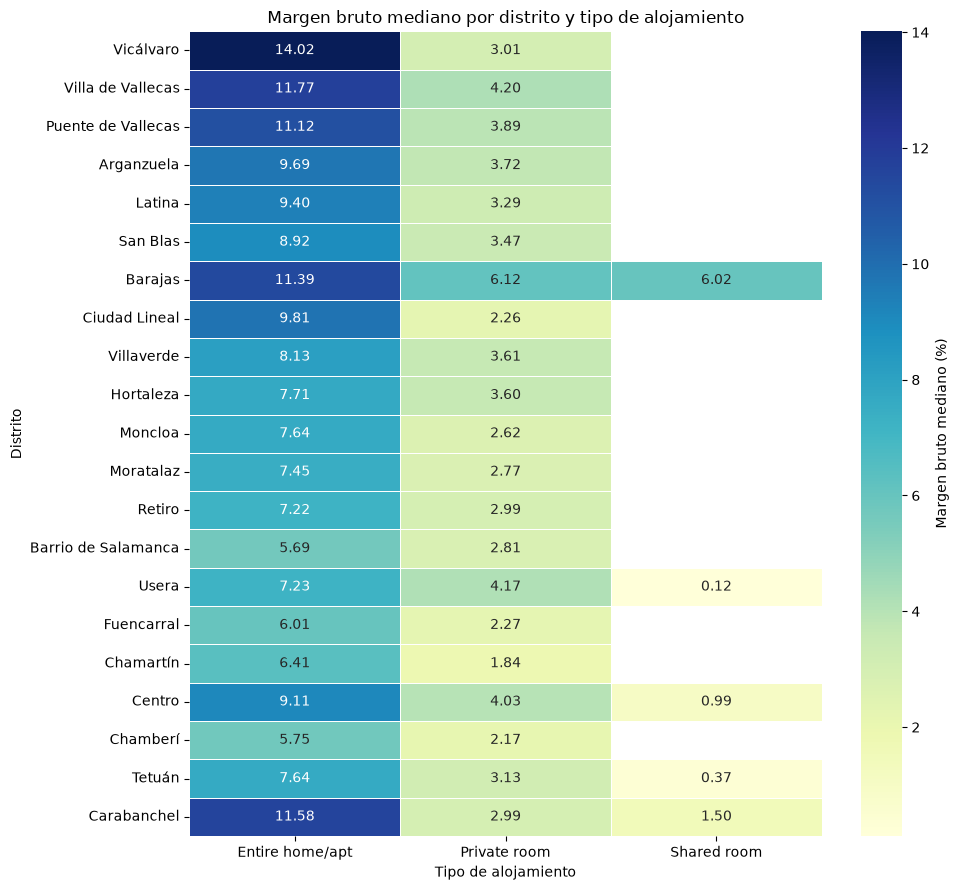

In [102]:
margen_heatmap = df.pivot_table(
index="neighbourhood_group",
columns="room_type",
values="margen_bruto",
aggfunc="median",
)

# Ordenar los distritos por su margen bruto mediano
margen_heatmap = margen_heatmap.loc[
margen_heatmap.median(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(10, 9))
sns.heatmap(
margen_heatmap,
annot=True,
fmt=".2f",
cmap="YlGnBu",
linewidths=0.5,
cbar_kws={"label": "Margen bruto mediano (%)"},
)
plt.title("Margen bruto mediano por distrito y tipo de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Distrito")
plt.tight_layout()
plt.show()

In [103]:
ranking_combinaciones = (
    df.groupby(
        [
            "neighbourhood_group",
            "neighbourhood",
            "bedrooms_category",
            "accommodates_category",
        ],
        dropna=False,
    )
    .agg(
        margen_bruto_mediano=("margen_bruto", "median"),
        ocupacion_mediana=("estimated_occupancy_l365d", "median"),
        anuncios=("id", "nunique"),
    )
    .sort_values("margen_bruto_mediano", ascending=False)
    .head(30)
)

display(ranking_combinaciones.round(2))

margen_bruto_mediano  \
neighbourhood_group neighbourhood                bedrooms_category accommodates_category                         
Latina              Aluche                       2 rooms           5+ accommodates                       44.10   
Usera               Zofío                        2 rooms           4 accommodates                        36.62   
Carabanchel         Comillas                     1 room            5+ accommodates                       34.28   
Usera               Pradolongo                   1 room            5+ accommodates                       33.18   
Puente de Vallecas  Portazgo                     2 rooms           4 accommodates                        32.41   
Usera               Orcasur                      3 rooms           5+ accommodates                       30.93   
                    Almendrales                  2 rooms           3 accommodates                        29.51   
Ciudad Lineal       Quintana                     4 rooms           5+ accommodates                       24.43   
Puente de Vallecas  Palomeras Bajas              1 room            5+ accommodates                       24.05   
Carabanchel         Comillas                     1 room            3 accommodates                        23.81   
Arganzuela          Atocha                       1 room            3 accommodates                        23.11   
Moncloa             Ciudad Universitaria         1 room            4 accommodates                        22.94   
Villaverde          San Cristobal                2 rooms           4 accommodates                        22.65   
Hortaleza           Piovera                      1 room            5+ accommodates                       22.49   
San Blas            Canillejas                   2 rooms           4 accommodates                        22.46   
Villa de Vallecas   Santa Eugenia                2 rooms           5+ accommodates                       22.27   
Villaverde          Los Rosales                  1 room            4 accommodates                        21.96   
Usera               Zofío                        2 rooms           5+ accommodates                       21.92   
Carabanchel         Buenavista                   1 room            4 accommodates                        21.51   
Tetuán              Cuatro Caminos               4 rooms           5+ accommodates                       21.34   
Puente de Vallecas  Portazgo                     2 rooms           5+ accommodates                       21.27   
Ciudad Lineal       Costillares                  2 rooms           5+ accommodates                       20.96   
Puente de Vallecas  Palomeras Bajas              1 room            4 accommodates                        20.39   
Barajas             Aeropuerto                   1 room            4 accommodates                        20.25   
Usera               Pradolongo                   2 rooms           4 accommodates                        19.96   
                    Orcasur                      1 room            5+ accommodates                       19.94   
Villa de Vallecas   Casco Histórico de Vallecas  2 rooms           3 accommodates                        19.77   
Vicálvaro           Casco Histórico de Vicálvaro 1 room            4 accommodates                        19.54   
Moncloa             El Plantío                   1 room            2 accommodates                        19.00   
Usera               Pradolongo                   1 room            4 accommodates                        18.93   

                                                                                          ocupacion_mediana  \
neighbourhood_group neighbourhood                bedrooms_category accommodates_category                      
Latina              Aluche                       2 rooms           5+ accommodates                    255.0   
Usera               Zofío                        2 rooms           4 accommodates                     229.5 

In [109]:

import folium
import branca.colormap as bcm
import pandas as pd

# Columnas necesarias
columnas_mapa = [
    "latitude", "longitude", "margen_bruto",
    "id", "name", "neighbourhood_group", "neighbourhood",
    "estimated_occupancy_l365d"
]

# Crear dataframe para el mapa
datos_mapa = df[columnas_mapa].copy()

# Convertir variables numéricas
columnas_numericas = [
    "latitude", "longitude", "margen_bruto",
    "estimated_occupancy_l365d"
]

for columna in columnas_numericas:
    datos_mapa[columna] = pd.to_numeric(
        datos_mapa[columna], errors="coerce"
    )

# Filtrar anuncios con ocupación estimada >= 150
datos_mapa = datos_mapa[
    datos_mapa["estimated_occupancy_l365d"] >= 150
].copy()

# Eliminar registros sin coordenadas o margen bruto
datos_mapa = datos_mapa.dropna(
    subset=["latitude", "longitude", "margen_bruto"]
)

if datos_mapa.empty:
    print("No hay anuncios que cumplan los filtros establecidos.")

else:
    # Percentiles para reducir el efecto de valores extremos
    minimo_color = datos_mapa["margen_bruto"].quantile(0.02)
    maximo_color = datos_mapa["margen_bruto"].quantile(0.98)

    # Evitar una escala inválida si todos los valores son iguales
    if minimo_color == maximo_color:
        maximo_color += 0.01

    escala_margen = bcm.LinearColormap(
        colors=[
            "#fff7bc", "#fec44f", "#fe9929",
            "#ec7014", "#cc4c02", "#8c2d04"
        ],
        vmin=minimo_color,
        vmax=maximo_color,
        caption="Margen bruto (%) — percentiles 2–98"
    )

    # Crear mapa
    mapa_margen = folium.Map(
        location=[
            datos_mapa["latitude"].mean(),
            datos_mapa["longitude"].mean()
        ],
        zoom_start=11,
        tiles=None
    )

    # Añadir cartografía Esri
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri",
        name="Esri World Street Map",
        overlay=False,
        control=False
    ).add_to(mapa_margen)

    # Añadir todos los marcadores
    for anuncio in datos_mapa.itertuples(index=False):

        color = escala_margen(
            min(
                max(anuncio.margen_bruto, minimo_color),
                maximo_color
            )
        )

        folium.CircleMarker(
            location=[
                anuncio.latitude,
                anuncio.longitude
            ],
            radius=5,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75,
            weight=1,
            tooltip=(
                f"{anuncio.name} | "
                f"Margen bruto: {anuncio.margen_bruto:.2f}%"
            ),
            popup=(
                f"<b>{anuncio.name}</b><br>"
                f"Distrito: {anuncio.neighbourhood_group}<br>"
                f"Barrio: {anuncio.neighbourhood}<br>"
                f"Margen bruto: {anuncio.margen_bruto:.2f}%<br>"
                f"Ocupación estimada: "
                f"{anuncio.estimated_occupancy_l365d:.0f}"
            )
        ).add_to(mapa_margen)

    # Añadir leyenda
    escala_margen.add_to(mapa_margen)

    # Mostrar mapa
    print(f"Anuncios representados: {len(datos_mapa)}")
    display(mapa_margen)


Anuncios representados: 5588


In [110]:
mapa_margen.save("mapa_margen.html")